# City Magnets in Yogyakarta — Visual Analytics (Role 4)
Explore relative mobile device presence across $500\text{ m} \times 500\text{ m}$ grid cells and the hourly rhythms of *kapanewon* across the Special Region of Yogyakarta (DIY). Set the sampling period below and run all cells to reproduce the interactive map and all four static figures.

In [1]:
from pathlib import Path
import os, sys
import pandas as pd
from IPython.display import display, Image, IFrame

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
from src.visualize import build, gold

period = '2021_Dec'
map_file, weekly, nataru, hourly, pull_fig = build(period, map_period='2022_Feb_P1')
for p in (map_file, pull_fig, weekly, nataru, hourly):
    print(p.relative_to(root), f'({p.stat().st_size / 1024:.1f} KB)')

figures/city_magnets_map.html (27354.7 KB)
figures/facility_pull.png (262.1 KB)
figures/weekday_weekend_ratio.png (226.4 KB)
figures/nataru_timeseries.png (316.5 KB)
figures/kapanewon_diurnal_heatmap.png (257.7 KB)


## 1. Interactive 500 m Spatial Map (`figures/city_magnets_map.html`)
Switch between facility categories and sampling periods in the layer control, or use **Color by** to inspect weekday and weekend publication coverage. Hover or click a $500\text{ m}$ square to see its mapped sites, coverage, and weekday vs. weekend relative shares. Each cell includes observed residents, visitors, and passersby.

**What we built.** An offline-ready Leaflet map of 5,715 grid squares with DIY regency boundaries, optional online street basemap, deduplicated OSM facility footprints, and the 9 audited DIY landmarks. **What we found.** In February 1–15, 2022, 1,628 squares cleared the $\ge 90\%$ weekday and weekend coverage bar: 829 leaned weekday ($\ge 1.05$), 498 leaned weekend ($< 0.95$), and 301 were near parity.

In [2]:
display(IFrame(os.path.relpath(map_file).replace(os.sep, '/'), width='100%', height=580))

## 2. Facility Pull — Relative Presence Share by Category (`figures/facility_pull.png`, RQ1)
Compares the median ordinary-weekday restricted presence share (%) across facility categories within each primary sampling period, alongside 95% site-cluster bootstrap confidence intervals and weekend median shares.

**What we built.** A 4-period comparison of category presence shares against unmapped baseline candidate cells. **What we found.** Mall-associated and campus-associated cells consistently drew higher relative weekday presence shares than unmapped baseline candidates across all four primary periods, while observational 1:1 matched comparisons (`matched_comparison.parquet`) confirm positive differences for campuses with residual activity imbalance disclosed below.

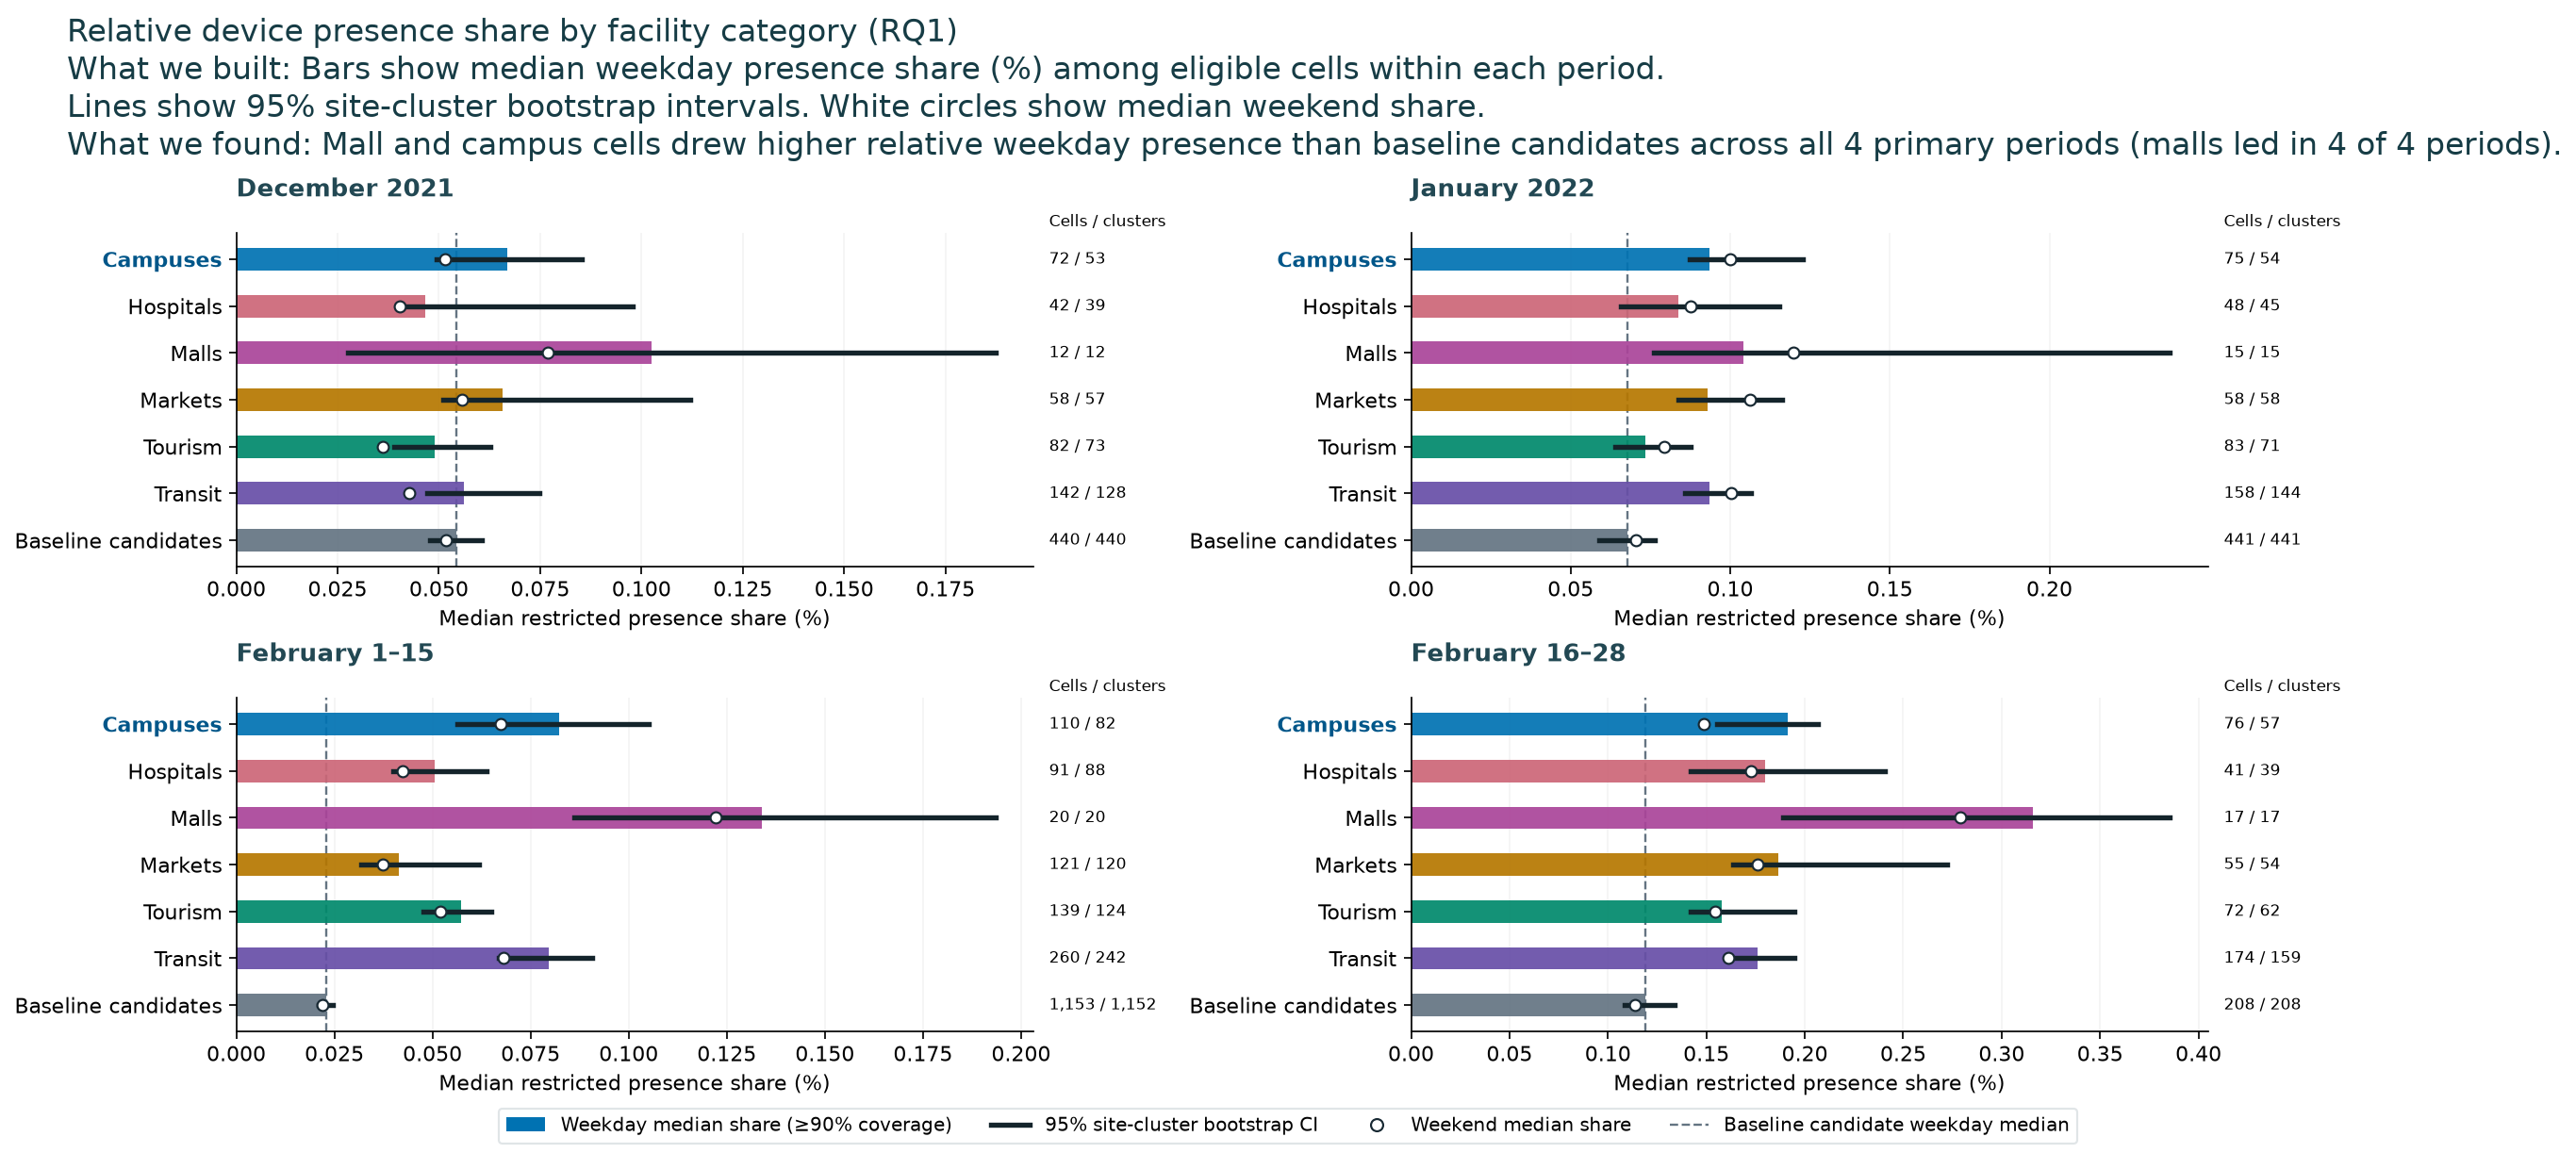

In [3]:
display(Image(filename=str(pull_fig)))

In [4]:
matched = gold('matched_comparison', 'sampling_period category treated_cells matched_pairs outside_common_support median_difference ci_low ci_high smd_activity_after evidence')
display(matched[matched['sampling_period'].isin(['2021_Dec', '2022_Feb_P1'])][['sampling_period', 'category', 'treated_cells', 'matched_pairs', 'outside_common_support', 'median_difference', 'ci_low', 'ci_high', 'smd_activity_after', 'evidence']])

,sampling_period,category,treated_cells,matched_pairs,outside_common_support,median_difference,ci_low,ci_high,smd_activity_after,evidence
0,2021_Dec,commercial_mall,12,3,0,NaN,NaN,NaN,NaN,withheld: fewer than 20 matched pairs
1,2021_Dec,education_campus,72,66,2,0.134845,-0.046141,0.215043,0.124525,observational
2,2021_Dec,healthcare_hospital,42,25,3,0.134223,-0.043582,0.322251,0.042242,observational
3,2021_Dec,tourism_site,82,31,4,0.094248,-0.141509,0.202857,-0.384703,observational
4,2021_Dec,traditional_market,58,28,2,0.001880,-0.290834,0.132404,0.047300,observational
5,2021_Dec,transit_hub,142,34,6,0.000000,0.000000,0.168575,0.017053,observational
6,2022_Feb_P1,commercial_mall,20,15,2,NaN,NaN,NaN,NaN,withheld: fewer than 20 matched pairs
7,2022_Feb_P1,education_campus,110,100,9,0.081292,-0.002315,0.115591,0.102262,observational
8,2022_Feb_P1,healthcare_hospital,91,83,5,0.028262,-0.064254,0.063130,0.260315,observational
9,2022_Feb_P1,tourism_site,139,100,6,0.048490,-0.003435,0.099425,0.365872,observational


## 3. Weekly Rhythm — Weekday-to-Weekend Ratio (`figures/weekday_weekend_ratio.png`, RQ2: H1–H3)
Ratios above $1.0$ indicate a higher ordinary-weekday relative share than ordinary-weekend share within the same sampling period. Categories overlap on mixed-use cells; white diamonds ($\diamond$) show the single-category subset and black lines show the 95% site-cluster bootstrap confidence intervals.

**What we built.** A period-separated weekday/weekend ratio chart with single-category sensitivity overlays and cell/cluster sample sizes. **What we found.** Campus cells (H1) leaned weekday ($> 1.0$) in all four primary periods (strongest in Dec 2021 at $1.29$, Feb 1–15 at $1.15$, and Feb 16–28 at $1.14$, dipping near parity $1.02$ during the Jan 2022 academic break), and their ranking holds across $80\%$, $90\%$, and $95\%$ coverage thresholds.

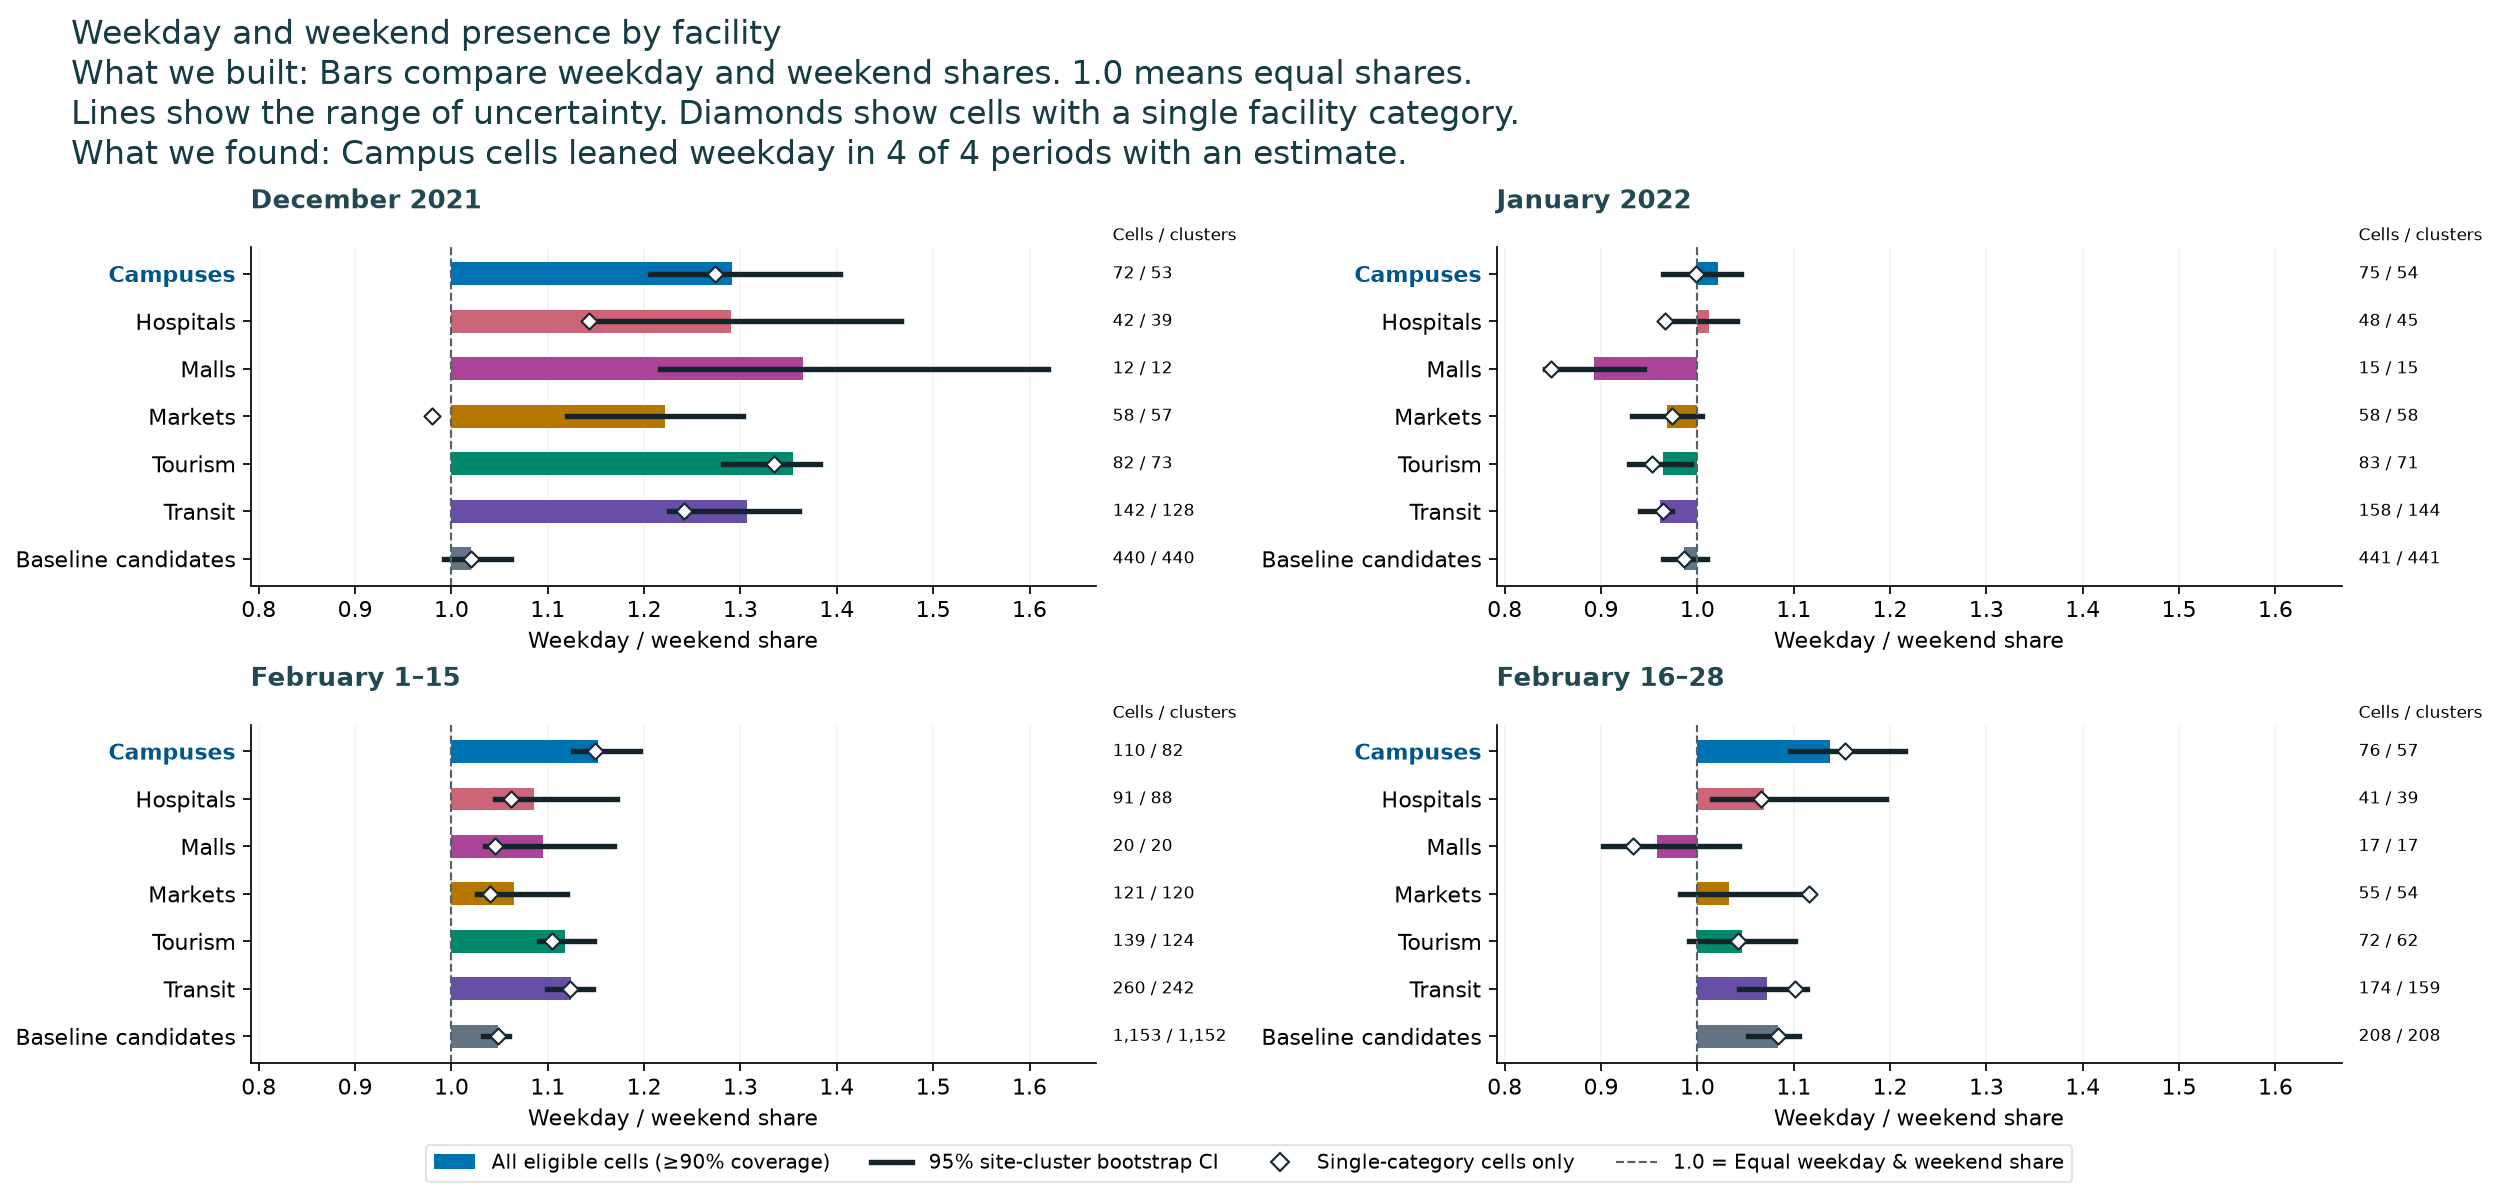

In [5]:
display(Image(filename=str(weekly)))

In [6]:
cov_sens = gold('coverage_sensitivity', 'sampling_period category coverage_threshold cells_with_ratio clusters median_ratio evidence')
display(cov_sens.pivot_table(index='category', columns='coverage_threshold', values='median_ratio', aggfunc='median').round(3))

coverage_threshold,80,90,95
category,,,
baseline_candidate,1.029,1.035,1.019
commercial_mall,1.023,1.027,1.023
education_campus,1.132,1.145,1.142
healthcare_hospital,1.063,1.077,1.075
tourism_site,1.069,1.082,1.079
traditional_market,1.040,1.049,1.038
transit_hub,1.088,1.098,1.095


## 4. Holiday Shockwave — Christmas & New Year (`figures/nataru_timeseries.png`, RQ3)
Each Nataru event day (24 Dec 2021 – 2 Jan 2022) is compared against non-event days of the **same day of the week** within the **same sampling period**. The lower panel displays daily grid publication coverage (% of 5,715 cells). **1 January 2022** is a known upstream panel discontinuity and is explicitly withheld.

**What we built.** Small-multiple relative presence curves with cell support counts and a synchronized coverage panel. **What we found.** Tourism cells rose to $29\%$ above their matched Saturday baseline on Christmas Day (25 Dec) before dropping $36\%$ below baseline on 29 Dec; no single holiday-uplift index is claimed across the 1 January sample break.

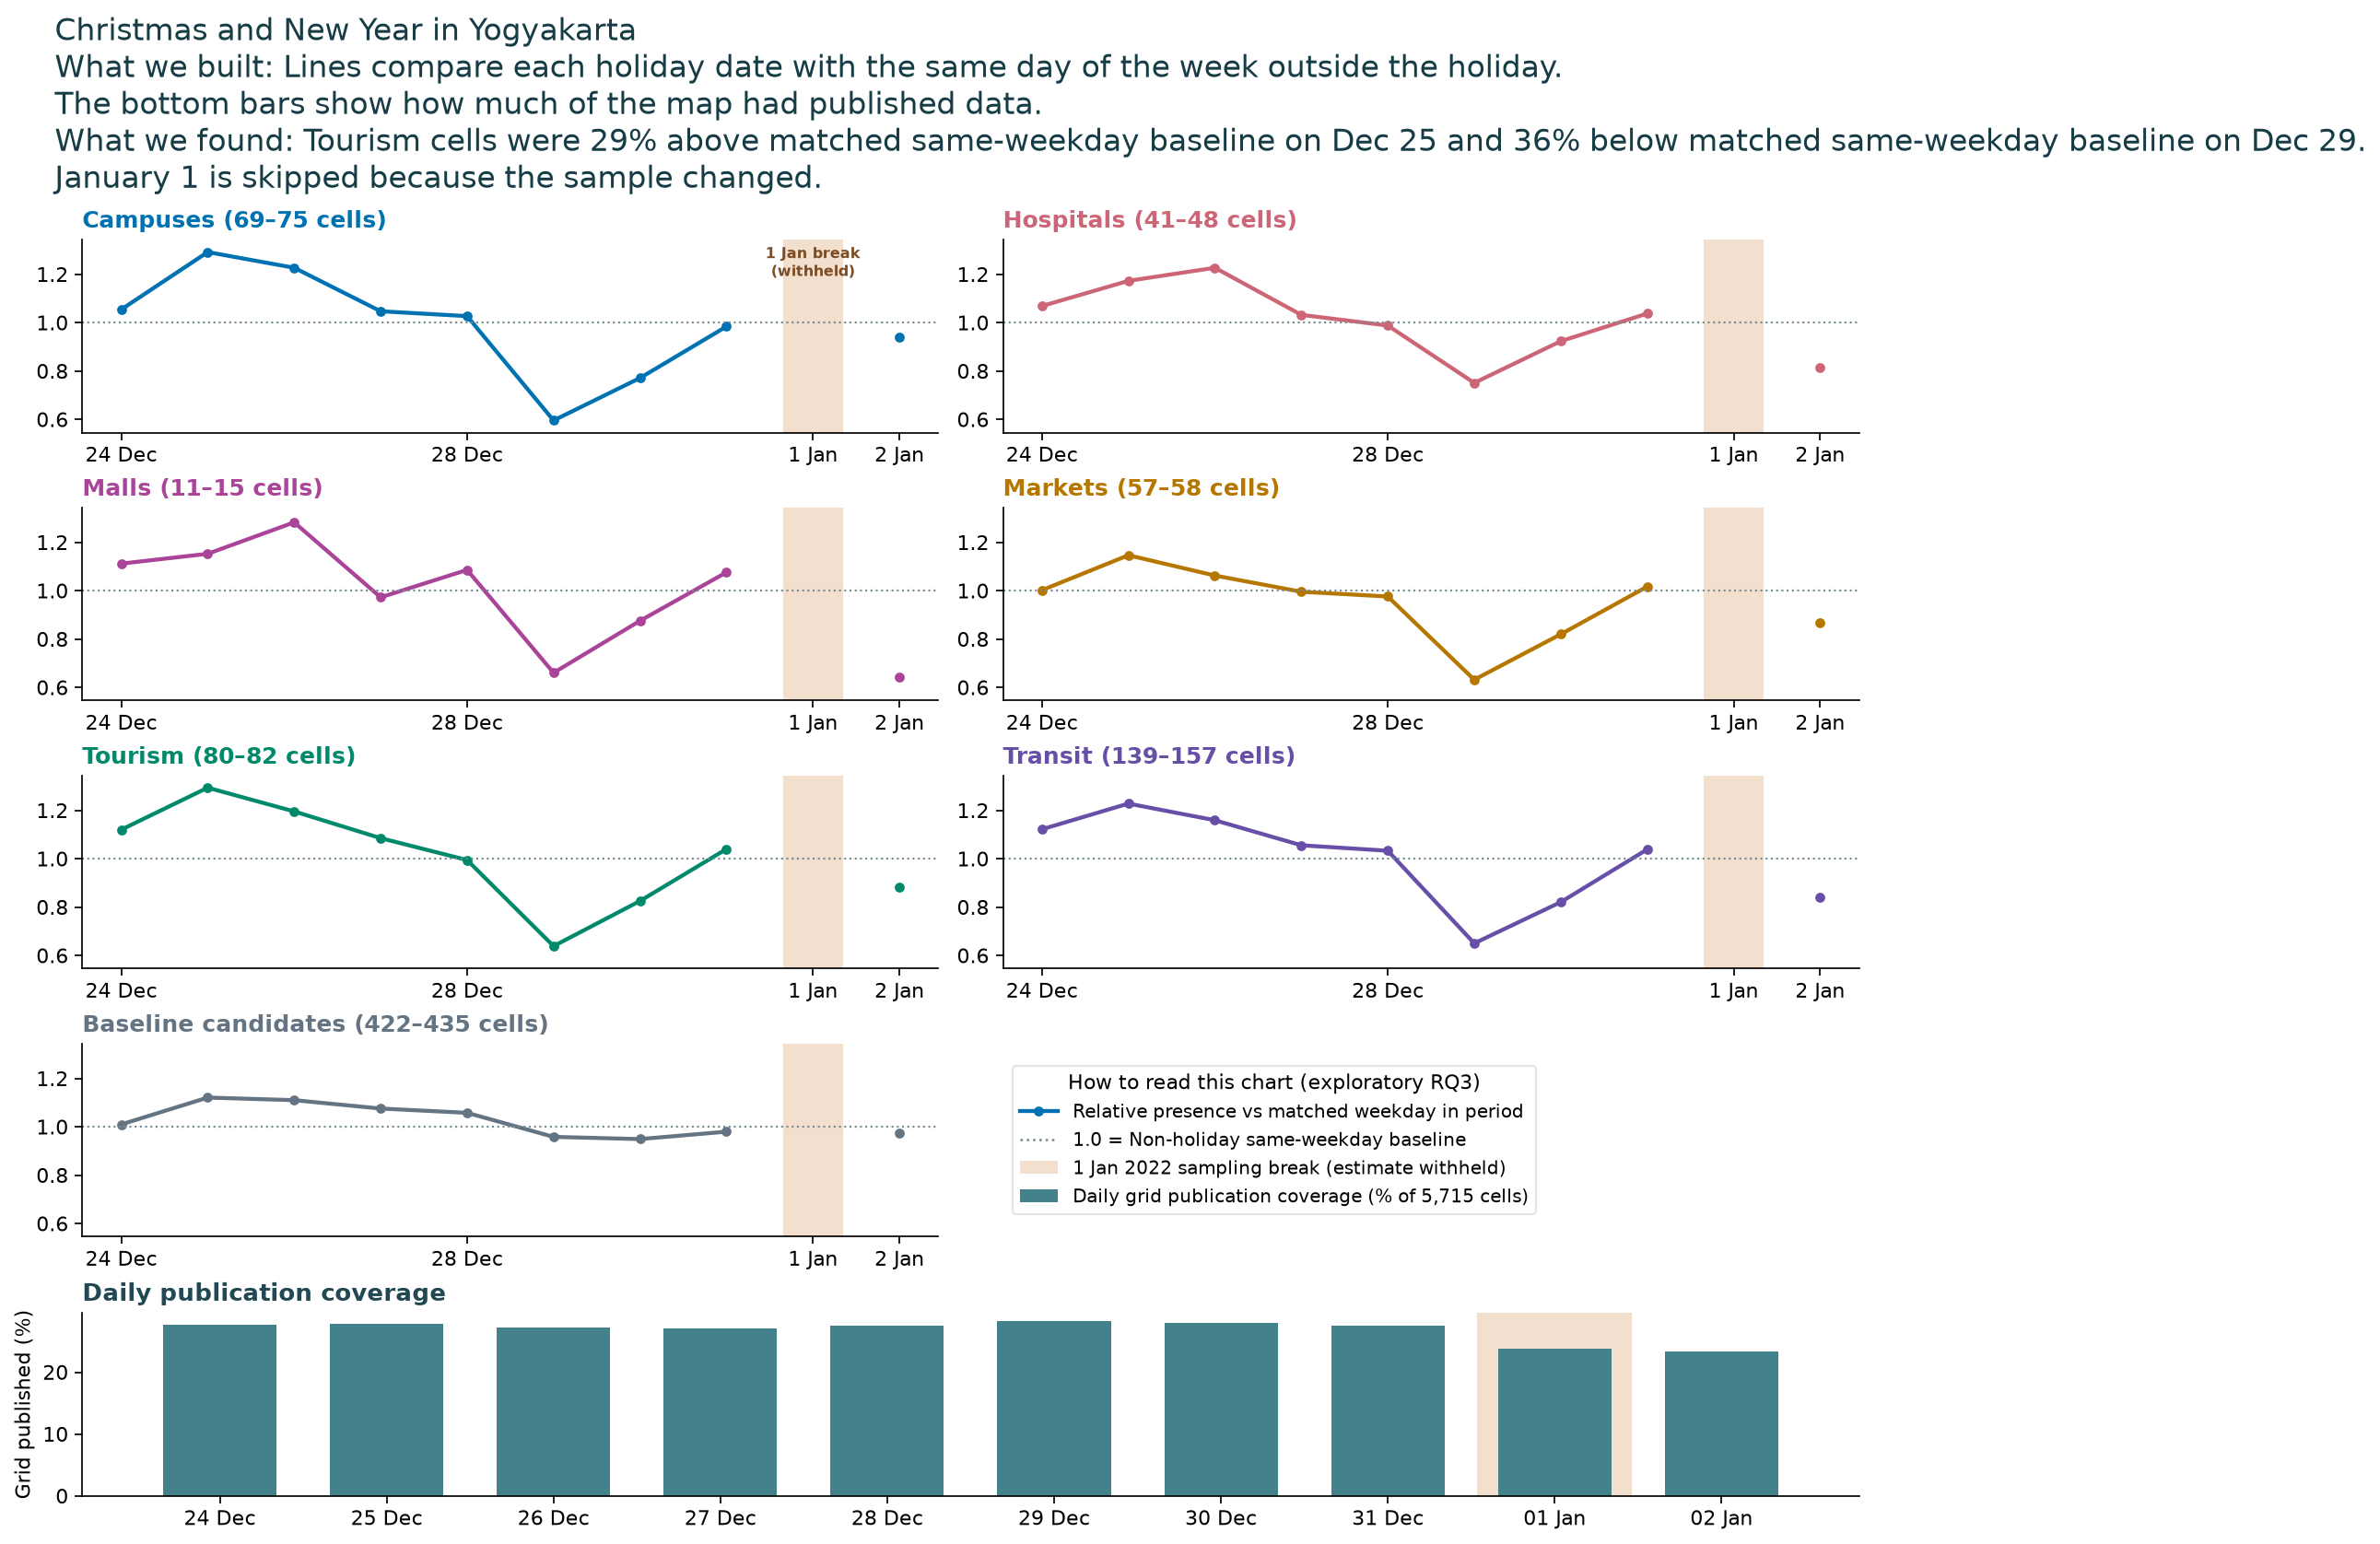

In [7]:
display(Image(filename=str(nataru)))

In [8]:
support = gold('event_window', 'date category cells_with_support median_baseline_days median_relative_presence evidence')
display(support[support['category'].isin(['tourism_site', 'commercial_mall', 'education_campus'])][['date', 'category', 'cells_with_support', 'median_baseline_days', 'median_relative_presence', 'evidence']].head(15))

,date,category,cells_with_support,median_baseline_days,median_relative_presence,evidence
1,2021-12-24,commercial_mall,12,3.0,1.112479,exploratory
2,2021-12-24,education_campus,71,3.0,1.054817,exploratory
4,2021-12-24,tourism_site,82,3.0,1.120639,exploratory
8,2021-12-25,commercial_mall,11,3.0,1.153122,exploratory
9,2021-12-25,education_campus,69,3.0,1.292314,exploratory
11,2021-12-25,tourism_site,80,3.0,1.294309,exploratory
15,2021-12-26,commercial_mall,11,3.0,1.283215,exploratory
16,2021-12-26,education_campus,71,3.0,1.227467,exploratory
18,2021-12-26,tourism_site,80,3.0,1.196191,exploratory
22,2021-12-27,commercial_mall,12,3.0,0.973175,exploratory


## 5. Diurnal Pulse — 24-Hour Kapanewon Heatmap (`figures/kapanewon_diurnal_heatmap.png`, RQ4)
Hourly sub-district profiles across the 10 busiest well-covered *kapanewon* ($0\text{–}23\text{ WIB}$). The left panels show median distinct devices (`median_n_maids`) with white circles marking each district's peak hour; the right panels show reporting intensity (`median_pings_per_maid`), which diagnoses app background ping frequency rather than crowd size.

**What we built.** Shared-scale weekday and weekend diurnal heatmaps for device presence and ping intensity. **What we found.** In December 2021, weekday activity peaked at 12:00–13:00 WIB in major campus/urban corridors (Gamping $12\text{ p.m.} \rightarrow 11\text{ a.m.}$ on weekends; Depok $1\text{ p.m.}$), whereas residential commuter rings peaked in the evening on weekdays and shifted earlier on weekends (Banguntapan $7\text{ p.m.} \rightarrow 2\text{ p.m.}$).

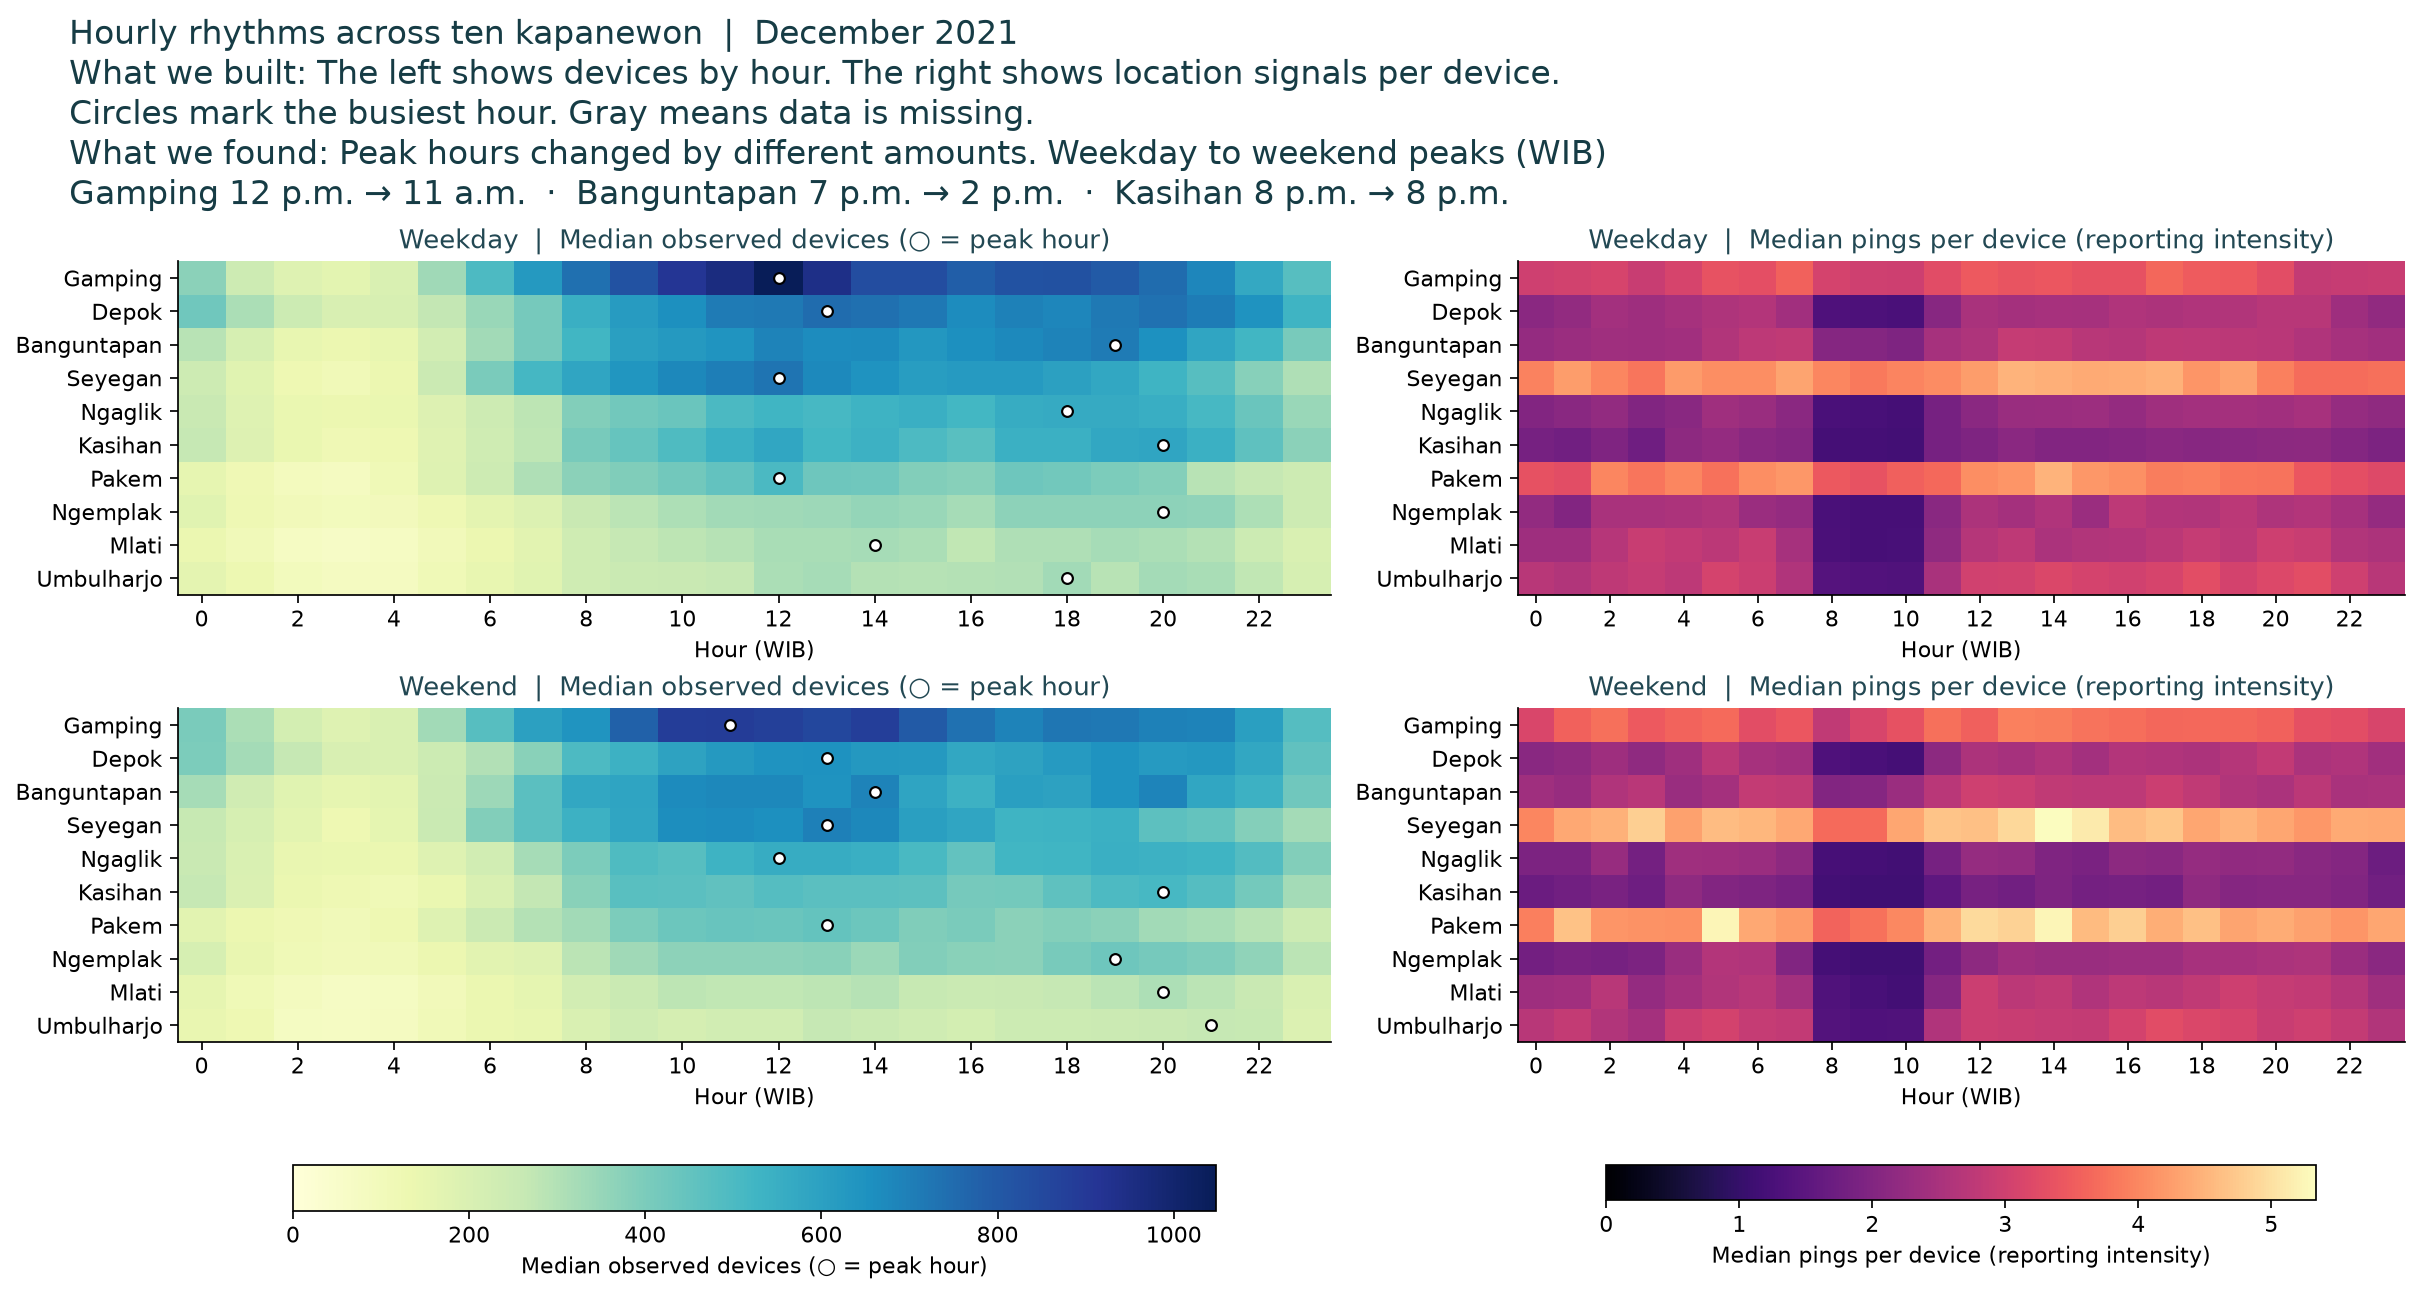

In [9]:
display(Image(filename=str(hourly)))